# 00 - Model verification and sanity checks

Before any sweep result is trusted, this notebook checks that the model code is the paper's model
and that the numerical settings do not affect the answers.

| # | Check | What it guards against |
|---|---|---|
| 1 | Code equations vs. an independent transcription of SI Eqs. S1-S10 | a mistyped term or sign |
| 2 | Reproduction of the paper's Fig. 2C time course | wrong parameters or initial conditions |
| 3 | Reproduction of Fig. 2D example runs and the Fig. 3A dose maps | wrong behaviour away from the base dose |
| 4 | Sweep engine (log coordinates) vs. reference model, all parameters and doses | an error in the fast engine |
| 5 | Two further stiff ODE solvers (Radau, BDF) at tight tolerance, against the sweep solver (LSODA) | solver-dependent results |
| 6 | Mass balance, enzyme balance, positivity, monotone antibiotic | unphysical trajectories |
| 7 | Exact identities and limits the equations must satisfy | structural errors |
| 8 | Sampling step and integration horizon | endpoint artefacts (missed dips, early stop) |
| 9 | Known behaviours of the model that need care | over-interpreting the plain ODE |

Every numerical check ends with an `assert`, so the notebook stops if one fails. The last cell
prints the full pass table.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
TABLES = PROJECT_ROOT / "results" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None); pd.set_option("display.width", 160)

from dataclasses import replace
from src.model.ma2024_model import (Params, DEFAULT_PARAMS, PARAM_NAMES, SI_RANDOMIZED_RANGES,
    SI_INITIAL_CONDITIONS, BASE_A0, BASE_I, default_y0, hill, rhs, simulate as simulate_linear,
    criterion_general)
from src.analysis import sweep_engine as engine
from src.analysis.grid_runner import axis, RANGES
from src.analysis.plotting import OKABE_ITO

P = DEFAULT_PARAMS
CHECKS = []
def record(name, value, limit, passed=None):
    passed = (value <= limit) if passed is None else passed
    CHECKS.append({"check": name, "value": value, "limit": limit, "pass": bool(passed)})
    assert passed, f"FAILED: {name}: {value} vs limit {limit}"
    print(f"PASS  {name}: {value:.3g} (limit {limit:g})")
print("Base parameters:", P)
print("Initial conditions:", SI_INITIAL_CONDITIONS, "| base dose a0 =", BASE_A0, ", i =", BASE_I)

Base parameters: Params(alpha=0.95, beta_min=0.9, c=0.7, gamma=1.38, h_a=3.0, h_i=2.0, kappa_b=0.35, d_a=0.02, d_b=1.0, xi=0.8, phi_max=1.0)
Initial conditions: {'ns0': 0.2, 'nr0': 0.2, 's0': 4.0, 'b0': 0.0} | base dose a0 = 2.15 , i = 10.0


## 1. Code equations vs. an independent transcription of the SI

`si_equations` below is typed directly from Supplementary Eqs. S1-S10, written differently from
`ma2024_model.rhs`. The two are compared at 2,000 random states and parameter sets.

In [2]:
def si_equations(ns, nr, s, a, b, i, alpha, beta_min, c, gamma, h_a, h_i, kappa_b, d_a, d_b, xi, phi_max):
    g = s / (1 + s)                                   # S6
    l = gamma * a**h_a / (1 + a**h_a) * g             # S7
    iota = i**h_i / (1 + i**h_i)                      # S8
    beta = beta_min + c * (1 - beta_min) * iota       # S9
    phi = phi_max * (1 - c * iota)                    # S10
    return np.array([
        (g - l) * ns,                                              # S1
        (alpha * g - beta * l) * nr,                               # S2
        (xi * l - g) * ns + (xi * beta * l - alpha * g) * nr,      # S3
        -kappa_b * b * a - phi * nr * a - d_a * a,                 # S4
        beta * l * nr - d_b * iota * b,                            # S5
    ])

rng = np.random.default_rng(0)
worst = 0.0
for over in engine.random_parameter_sets(2000, seed=1):
    state = [rng.uniform(0, 5), rng.uniform(0, 5), rng.uniform(0, 5), 10 ** rng.uniform(-2, 2), rng.uniform(0, 3)]
    i = 10 ** rng.uniform(-1, 1)
    p = replace(P, **over)
    ours = rhs(0.0, np.array(state), p, i)
    ref = si_equations(*state, i, **{k: getattr(p, k) for k in PARAM_NAMES})
    worst = max(worst, float(np.max(np.abs(ours - ref) / (1 + np.abs(ref)))))
record("1. rhs vs SI transcription (max relative difference)", worst, 1e-12)

PASS  1. rhs vs SI transcription (max relative difference): 1.27e-15 (limit 1e-12)


## 2. Reproduction of Fig. 2C (a0 = 2.15, i = 10, base parameters)

The paper's Fig. 2C shows both populations dipping, then regrowing to S a little above 2 and R a
little below 2 by t = 15-20, the antibiotic falling from 2.15 to 0, and the resistant fraction
drifting from 0.5 down to just above 0.4 (inset).

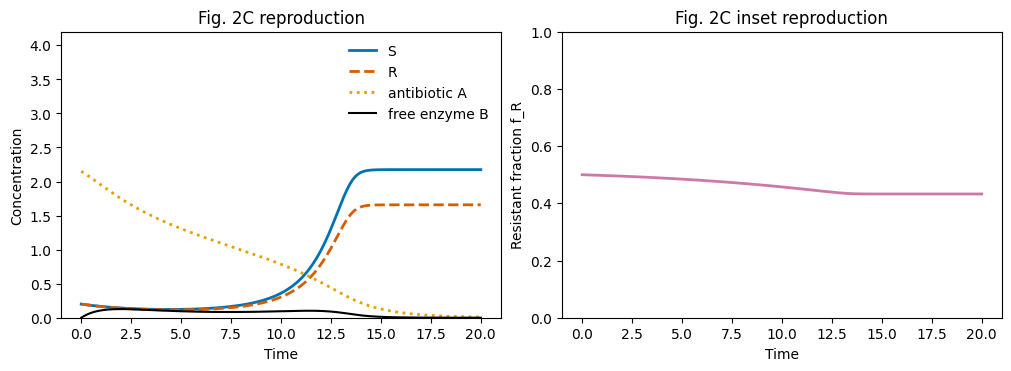

t = 20:  S = 2.175, R = 1.658, f_R = 0.433;  lowest S = 0.121 at t = 4.4
PASS  2. Fig. 2C: |S(20) - 2.2| read off the figure: 0.0254 (limit 0.15)
PASS  2. Fig. 2C: |R(20) - 1.7| read off the figure: 0.0423 (limit 0.15)
PASS  2. Fig. 2C inset: |f_R(20) - 0.43|: 0.00256 (limit 0.03)


In [3]:
tr = engine.simulate(P, BASE_A0, BASE_I, t_end=20, dt=0.02)
fR = tr.nr / (tr.ns + tr.nr)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
ax.plot(tr.t, tr.ns, color=OKABE_ITO["blue"], lw=2, label="S")
ax.plot(tr.t, tr.nr, color=OKABE_ITO["vermillion"], lw=2, ls="--", label="R")
ax.plot(tr.t, tr.a, color=OKABE_ITO["orange"], lw=2, ls=":", label="antibiotic A")
ax.plot(tr.t, tr.b, color="black", lw=1.5, label="free enzyme B")
ax.set(xlabel="Time", ylabel="Concentration", title="Fig. 2C reproduction", ylim=(0, 4.2)); ax.legend(frameon=False)
ax2.plot(tr.t, fR, color=OKABE_ITO["purple"], lw=2)
ax2.set(xlabel="Time", ylabel="Resistant fraction f_R", ylim=(0, 1), title="Fig. 2C inset reproduction")
plt.show()
print(f"t = 20:  S = {tr.ns[-1]:.3f}, R = {tr.nr[-1]:.3f}, f_R = {fR[-1]:.3f};  lowest S = {tr.ns.min():.3f} at t = {tr.t[tr.ns.argmin()]:.1f}")
record("2. Fig. 2C: |S(20) - 2.2| read off the figure", abs(tr.ns[-1] - 2.2), 0.15)
record("2. Fig. 2C: |R(20) - 1.7| read off the figure", abs(tr.nr[-1] - 1.7), 0.15)
record("2. Fig. 2C inset: |f_R(20) - 0.43|", abs(fR[-1] - 0.43), 0.03)

## 3. Reproduction of Fig. 2D example runs and the Fig. 3A dose maps

Fig. 2D highlights two runs. From the insets: **A = 100, I = 0.32** dips to roughly 10^-3 and ends
majority-resistant; **A = 6.8, I = 10** dips to roughly 10^-7-10^-6, recovers near t = 100 and ends
majority-sensitive.

The paper does not state the final time of its dose maps. The Fig. 2D insets run to about t = 100,
so the maps below are read at **t = 100** (an assumption). Four parameter sets are shown, one per
direction in Fig. 3A: base, higher burden (α = 0.8), higher private benefit (β_min = 0.7) and higher
inhibition (c = 0.9). The paper gives no numbers for its panels, so these three values are the group's
choices; the β_min panel is the mirror image of the paper's, which shows a lower private benefit. The
Fig. 2D doses and dip depths above are read off the figure.

In [4]:
for a0, i, expect in [(100.0, 0.32, "majority resistant"), (6.8, 10.0, "majority sensitive")]:
    r = engine.compute_endpoints(a0=a0, i_dose=i)
    print(f"A = {a0:g}, I = {i:g}: lowest total = {r['total_min']:.1e}, settles at t = {r['t_steady_state']:.0f}, "
          f"final f_R = {r['f_R_final']:.2f}  ({expect} in the paper)")
r1 = engine.compute_endpoints(a0=100.0, i_dose=0.32); r2 = engine.compute_endpoints(a0=6.8, i_dose=10.0)
record("3. Fig. 2D: A=100, I=0.32 ends majority resistant", 1 - r1["f_R_final"], 0.5)
record("3. Fig. 2D: A=6.8, I=10 ends majority sensitive", r2["f_R_final"], 0.5)
record("3. Fig. 2D: A=100, I=0.32 lowest density within 10x of 1e-3", abs(np.log10(r1["total_min"] / 1e-3)), 1.0)
record("3. Fig. 2D: A=6.8, I=10 lowest density within 10x of 1e-6", abs(np.log10(r2["total_min"] / 1e-6)), 1.0)

A = 100, I = 0.32: lowest total = 6.1e-04, settles at t = 58, final f_R = 0.86  (majority resistant in the paper)
A = 6.8, I = 10: lowest total = 2.4e-06, settles at t = 103, final f_R = 0.16  (majority sensitive in the paper)
PASS  3. Fig. 2D: A=100, I=0.32 ends majority resistant: 0.139 (limit 0.5)
PASS  3. Fig. 2D: A=6.8, I=10 ends majority sensitive: 0.162 (limit 0.5)
PASS  3. Fig. 2D: A=100, I=0.32 lowest density within 10x of 1e-3: 0.211 (limit 1)
PASS  3. Fig. 2D: A=6.8, I=10 lowest density within 10x of 1e-6: 0.386 (limit 1)


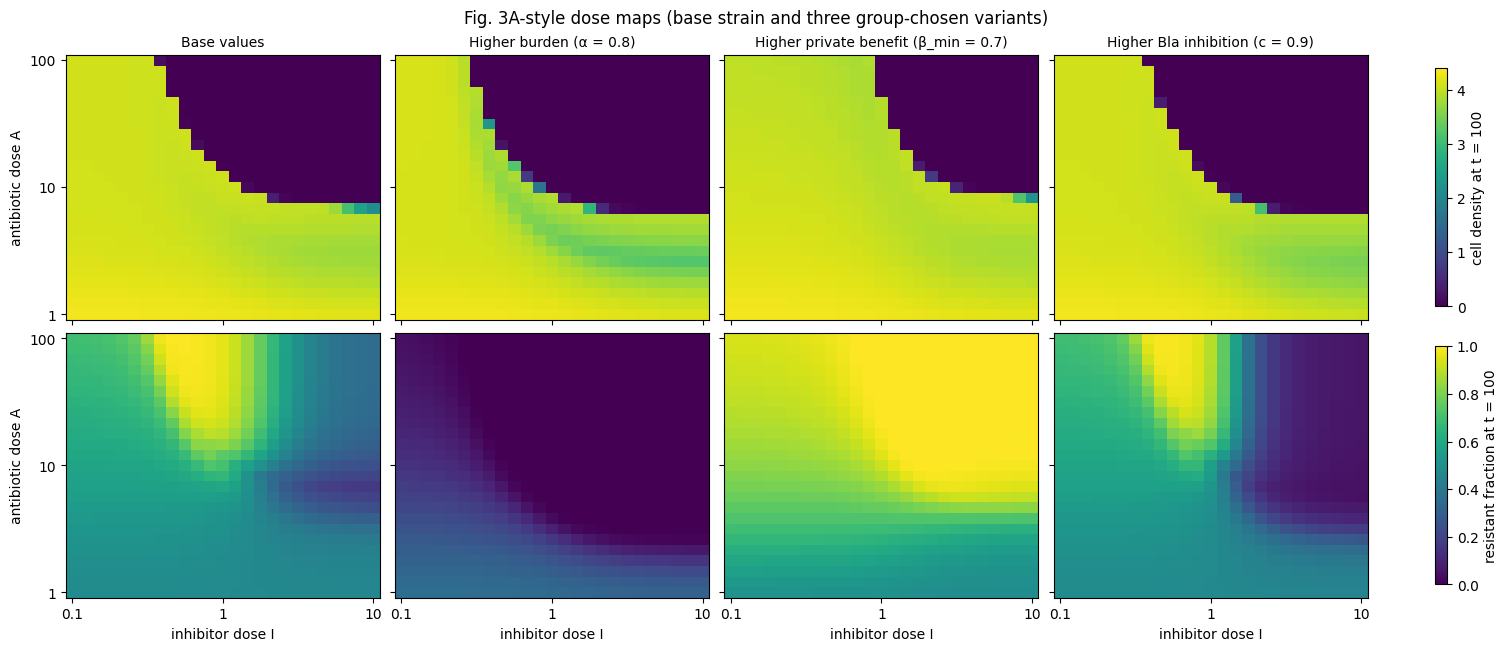

Higher burden (α = 0.8): mean shift in resistant fraction = -0.468; doses going the other way by more than 0.01: 0.0%
PASS  3. Fig. 3A: 'Higher burden (α = 0.8)' lowers the resistant fraction at almost all doses (share going the other way): 0 (limit 0.1)
Higher Bla inhibition (c = 0.9): mean shift in resistant fraction = -0.105; doses going the other way by more than 0.01: 0.0%
PASS  3. Fig. 3A: 'Higher Bla inhibition (c = 0.9)' lowers the resistant fraction at almost all doses (share going the other way): 0 (limit 0.1)
Higher private benefit (β_min = 0.7): mean shift in resistant fraction = +0.268; doses going the other way by more than 0.01: 1.6%
PASS  3. Fig. 3A: 'Higher private benefit (β_min = 0.7)' raises the resistant fraction at almost all doses (share going the other way): 0.016 (limit 0.1)


In [5]:
T_MAP = 100.0
a_axis, i_axis = np.geomspace(1, 100, 25), np.geomspace(0.1, 10, 25)
panels = [("Base values", {}), ("Higher burden (α = 0.8)", {"alpha": 0.8}),
          ("Higher private benefit (β_min = 0.7)", {"beta_min": 0.7}), ("Higher Bla inhibition (c = 0.9)", {"c": 0.9})]
maps = {}
for name, over in panels:
    dens, frac = np.zeros((25, 25)), np.zeros((25, 25))
    for r, a0 in enumerate(a_axis):
        for c_, i in enumerate(i_axis):
            t_ = engine.integrate(replace(P, **over), a0, i, stages=((T_MAP, 1.0),), adaptive=False)
            dens[r, c_] = t_.ns[-1] + t_.nr[-1]
            frac[r, c_] = np.exp(t_.ln_nr[-1]) / (np.exp(t_.ln_ns[-1]) + np.exp(t_.ln_nr[-1]))
    maps[name] = (dens, frac)

fig, axes = plt.subplots(2, 4, figsize=(15, 6.4), constrained_layout=True, sharex=True, sharey=True)
for j, (name, _) in enumerate(panels):
    dens, frac = maps[name]
    m1 = axes[0, j].pcolormesh(np.log10(i_axis), np.log10(a_axis), dens, cmap="viridis", vmin=0, vmax=4.4, shading="nearest")
    m2 = axes[1, j].pcolormesh(np.log10(i_axis), np.log10(a_axis), frac, cmap="viridis", vmin=0, vmax=1, shading="nearest")
    axes[0, j].set_title(name, fontsize=10)
    axes[1, j].set_xlabel("inhibitor dose I"); axes[1, j].set_xticks([-1, 0, 1]); axes[1, j].set_xticklabels(["0.1", "1", "10"])
for ax in axes[:, 0]:
    ax.set_ylabel("antibiotic dose A"); ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["1", "10", "100"])
fig.colorbar(m1, ax=axes[0], shrink=0.9).set_label(f"cell density at t = {T_MAP:g}")
fig.colorbar(m2, ax=axes[1], shrink=0.9).set_label(f"resistant fraction at t = {T_MAP:g}")
fig.suptitle("Fig. 3A-style dose maps (base strain and three group-chosen variants)", fontsize=12)
plt.show()

base_frac = maps["Base values"][1]
for name, sign in [("Higher burden (α = 0.8)", -1), ("Higher Bla inhibition (c = 0.9)", -1),
                   ("Higher private benefit (β_min = 0.7)", +1)]:
    shift = sign * (maps[name][1] - base_frac)          # positive = the direction the paper reports
    wrong_way = float(np.mean(shift < -0.01))
    word = "lowers" if sign < 0 else "raises"
    print(f"{name}: mean shift in resistant fraction = {sign * shift.mean():+.3f}; "
          f"doses going the other way by more than 0.01: {wrong_way:.1%}")
    record(f"3. Fig. 3A: '{name}' {word} the resistant fraction at almost all doses (share going the other way)",
           wrong_way, 0.10)

The maps have the paper's features: a staircase boundary beyond which the population is still
suppressed at the read-out time, resistant-dominated (yellow) outcomes at high antibiotic with little
inhibitor, and sensitive-dominated (dark) outcomes at high inhibitor. A larger burden or stronger
intracellular inhibition lowers the resistant fraction, and a larger private benefit raises it, at
almost all doses, in line with the directions the paper reports for Fig. 3A.

## 4. Sweep engine vs. reference model (all parameters and both doses)

The sweeps use `sweep_engine.integrate`, which carries ln(n_s) and ln(n_r). It is compared with the
linear-coordinate reference model at 60 random points drawn over **all 11 parameters and both
doses** (the earlier check only varied alpha, beta_min and c).

In [6]:
worst = engine.verify_equivalence(n_checks=60, seed=3)
print("Worst |difference| / (1e-6 + 1e-4 |reference|) per variable (must be <= 1):", {k: round(v, 4) for k, v in worst.items()})
record("4. engine vs reference model (worst normalised difference)", max(worst.values()), 1.0)

Worst |difference| / (1e-6 + 1e-4 |reference|) per variable (must be <= 1): {'ns': 0.0145, 'nr': 0.0079, 's': 0.0094, 'a': 0.0032, 'b': 0.0044}
PASS  4. engine vs reference model (worst normalised difference): 0.0145 (limit 1)


## 5. Solver independence

The same 25 random runs with two further stiff solvers (Radau, BDF) at tight tolerance, compared with the sweep settings (LSODA, rtol 1e-8).

In [7]:
rng = np.random.default_rng(5)
rows = []
for over in engine.random_parameter_sets(25, seed=5):
    a0, i = 10 ** rng.uniform(0, 2), 10 ** rng.uniform(-1, 1)
    p = replace(P, **over)
    base = engine.integrate(p, a0, i)
    if not base.converged:
        continue
    for method in ("Radau", "BDF"):
        alt = engine.integrate(p, a0, i, method=method, rtol=1e-10, atol=1e-13)   # same sampling times
        rows.append({"method": method,
                     "final S rel. diff": abs(alt.ns[-1] - base.ns[-1]) / base.ns[-1],
                     "final R rel. diff": abs(alt.nr[-1] - base.nr[-1]) / base.nr[-1],
                     "lowest S, log10 diff": abs(np.log10(alt.ns.min() / base.ns.min()))})
solver = pd.DataFrame(rows)
display(solver.groupby("method").max())
record("5. solver independence: final densities (max relative difference)",
       float(solver[["final S rel. diff", "final R rel. diff"]].max().max()), 1e-4)
record("5. solver independence: lowest S (max log10 difference)", float(solver["lowest S, log10 diff"].max()), 0.01)

,final S rel. diff,final R rel. diff,"lowest S, log10 diff"
method,,,
BDF,2.656810e-07,3.750152e-07,7.763657e-08
Radau,2.939256e-07,3.929736e-07,6.209733e-08


PASS  5. solver independence: final densities (max relative difference): 3.93e-07 (limit 0.0001)
PASS  5. solver independence: lowest S (max log10 difference): 7.76e-08 (limit 0.01)


## 6. Mass balance, enzyme balance and positivity

Adding Eqs. S1-S3 gives an exact budget: nutrient plus biomass, M = s + n_s + n_r, can only fall,
and it falls by the un-recycled part of lysed biomass:

dM/dt = -(1 - ξ) · l · (n_s + β n_r)

Likewise free enzyme obeys b(t) = ∫ β l n_r dt − ∫ d_b ι b dt. Both are checked along trajectories,
together with: the antibiotic never increases, and no state goes meaningfully negative.

In [8]:
def budgets(p, a0, i, t_end=60.0):
    t_ = engine.simulate(p, a0, i, t_end=t_end, dt=0.005)
    g = t_.s / (1 + t_.s); l = p.gamma * hill(t_.a, p.h_a) * g
    cum = lambda f: np.concatenate([[0.0], np.cumsum(0.5 * (f[1:] + f[:-1]) * np.diff(t_.t))])
    M = t_.s + t_.ns + t_.nr
    mass = np.max(np.abs(M + (1 - p.xi) * cum(l * (t_.ns + t_.beta * t_.nr)) - M[0]))
    iota = hill(i, p.h_i)
    enzyme = np.max(np.abs(t_.b - (cum(t_.beta * l * t_.nr) - p.d_b * iota * cum(t_.b))))
    return mass, enzyme, float(np.max(np.diff(t_.a))), float(min(t_.s.min(), t_.a.min(), t_.b.min())), float(np.max(np.diff(M)))

rng = np.random.default_rng(6)
res = np.array([budgets(replace(P, **over), 10 ** rng.uniform(0, 1.3), 10 ** rng.uniform(-1, 1))
                for over in engine.random_parameter_sets(40, seed=6)])
record("6. mass balance residual (40 random runs)", float(res[:, 0].max()), 1e-4)
record("6. enzyme balance residual", float(res[:, 1].max()), 1e-4)
record("6. antibiotic never increases (largest step up)", float(res[:, 2].max()), 1e-9)
record("6. most negative state value (magnitude)", float(-res[:, 3].min()), 1e-8)
record("6. nutrient + biomass never increases (largest step up)", float(res[:, 4].max()), 1e-8)

PASS  6. mass balance residual (40 random runs): 7.11e-07 (limit 0.0001)
PASS  6. enzyme balance residual: 3.33e-06 (limit 0.0001)
PASS  6. antibiotic never increases (largest step up): 6.18e-12 (limit 1e-09)
PASS  6. most negative state value (magnitude): 3.61e-10 (limit 1e-08)
PASS  6. nutrient + biomass never increases (largest step up): 7.3e-10 (limit 1e-08)


## 7. Exact identities and limits

Each of these follows from the equations and holds exactly, so any deviation is a bug.

- **No drug:** all nutrient becomes biomass, total = 4.4, and ln(n_r/n_r0) = α · ln(n_s/n_s0).
- **Identical strains** (α = 1, β_min = 1): the resistant fraction stays at 0.5 at any dose.
- **No inhibitor** (i = 0): results do not depend on c, h_i or d_b.
- **Inhibitor enters only through ι:** two (i, h_i) pairs with the same ι = i^h_i/(1 + i^h_i) give the same run.
- **Killing threshold:** S declines only while γ · a^h_a/(1 + a^h_a) > 1, i.e. a > (γ − 1)^(−1/h_a) = 1.38 at base.
- **Selection criterion (Eq. 1):** the sign of d ln(n_r/n_s)/dt from the code equals the paper's criterion.

In [9]:
t_ = engine.integrate(P, 0.0, 0.0)
record("7. no drug: |final total - 4.4|", abs(t_.ns[-1] + t_.nr[-1] - engine.CARRYING_CAPACITY), 1e-5)
record("7. no drug: ln(nr/nr0) - alpha ln(ns/ns0)", abs(np.log(t_.nr[-1] / 0.2) - P.alpha * np.log(t_.ns[-1] / 0.2)), 1e-8)

worst = 0.0
for a0 in (2.15, 10.0, 100.0):
    t_ = engine.integrate(replace(P, alpha=1.0, beta_min=1.0), a0, 10.0)
    worst = max(worst, float(np.max(np.abs(t_.ln_nr - t_.ln_ns))))
record("7. identical strains: max |ln(nr/ns)| at any time", worst, 1e-8)

ref = engine.integrate(P, 5.0, 0.0)
alt = engine.integrate(replace(P, c=0.1, h_i=4.0, d_b=7.0), 5.0, 0.0)
record("7. i = 0: independent of c, h_i, d_b (final S, R difference)",
       max(abs(ref.ns[-1] - alt.ns[-1]), abs(ref.nr[-1] - alt.nr[-1])), 1e-8)

t1 = engine.integrate(replace(P, h_i=1.0), 5.0, 2.0)             # iota = 2/3
t2 = engine.integrate(replace(P, h_i=2.0), 5.0, np.sqrt(2.0))    # iota = 2/3
record("7. same iota from different (i, h_i): final S, R difference",
       max(abs(t1.ns[-1] - t2.ns[-1]), abs(t1.nr[-1] - t2.nr[-1])), 1e-8)

a_star = (P.gamma - 1) ** (-1 / P.h_a)
below = engine.simulate(P, a_star * 0.99, 10.0, t_end=30, dt=0.01)
above = engine.simulate(P, a_star * 1.05, 10.0, t_end=30, dt=0.01)
print(f"Killing threshold a* = {a_star:.3f}: S loss just below = {1 - below.ns.min() / 0.2:.2e}, just above = {1 - above.ns.min() / 0.2:.2e}")
record("7. no S loss just below the killing threshold", 1 - below.ns.min() / 0.2, 1e-12)
record("7. S loss just above the killing threshold", 0.0, 0.0, passed=(1 - above.ns.min() / 0.2) > 1e-4)

rng = np.random.default_rng(7)
mismatch = 0
for over in engine.random_parameter_sets(3000, seed=7):
    p = replace(P, **over)
    s, a, i = rng.uniform(0.05, 5), 10 ** rng.uniform(-1, 2), 10 ** rng.uniform(-1, 1)
    d = rhs(0.0, np.array([1.0, 1.0, s, a, 0.0]), p, i)
    mismatch += (d[1] > d[0]) != criterion_general(p, s, a, i)
record("7. Eq. 1 vs sign of d ln(nr/ns)/dt (mismatches in 3,000 random states)", mismatch, 0)

PASS  7. no drug: |final total - 4.4|: 1.98e-07 (limit 1e-05)
PASS  7. no drug: ln(nr/nr0) - alpha ln(ns/ns0): 0 (limit 1e-08)
PASS  7. identical strains: max |ln(nr/ns)| at any time: 0 (limit 1e-08)
PASS  7. i = 0: independent of c, h_i, d_b (final S, R difference): 0 (limit 1e-08)
PASS  7. same iota from different (i, h_i): final S, R difference: 2.59e-13 (limit 1e-08)


Killing threshold a* = 1.381: S loss just below = 0.00e+00, just above = 8.53e-03
PASS  7. no S loss just below the killing threshold: 0 (limit 1e-12)
PASS  7. S loss just above the killing threshold: 0 (limit 0)
PASS  7. Eq. 1 vs sign of d ln(nr/ns)/dt (mismatches in 3,000 random states): 0 (limit 0)


## 8. Sampling step and integration horizon

Earlier notebooks disagreed here (fixed horizons of 150, 300 and 400; one stored a point only every
3.3 time units and missed short dips). The sweep engine samples every 0.5 at first and extends the
horizon until the populations settle. 200 random runs over all parameters and doses are compared
with a reference sampled every 0.02 and run twice as long.

In [10]:
rng = np.random.default_rng(8)
rows = []
for over in engine.random_parameter_sets(200, seed=8):
    a0, i = 10 ** rng.uniform(0, 2), 10 ** rng.uniform(-1, 1)
    p = replace(P, **over)
    tr1 = engine.integrate(p, a0, i)
    e1 = engine.endpoints(tr1)
    if e1["outcome"] in ("community collapsed", "not converged"):
        continue
    tr2 = engine.integrate(p, a0, i, stages=((2 * float(tr1.t[-1]), 0.02),), adaptive=False)
    e2 = engine.endpoints(tr2)
    rows.append({"horizon used": tr1.t[-1],
                 "final f_R": abs(e1["f_R_final"] - e2["f_R_final"]),
                 "final total (relative)": abs(e1["total_final"] - e2["total_final"]) / e2["total_final"],
                 "peak S loss": abs(e1["peak_loss_S"] - e2["peak_loss_S"]),
                 "S recovery time": abs(e1["t_regain_S"] - e2["t_regain_S"]) if np.isfinite(e2["t_regain_S"]) else 0.0,
                 "time to steady state": abs(e1["t_steady_state"] - e2["t_steady_state"])})
num = pd.DataFrame(rows)
print(f"{len(num)} settled runs compared; horizons used: {num['horizon used'].value_counts().to_dict()}")
display(num.drop(columns="horizon used").describe().loc[["mean", "max"]])
record("8. horizon: final f_R unchanged when run twice as long", float(num["final f_R"].max()), 1e-4)
record("8. horizon: final total unchanged (relative)", float(num["final total (relative)"].max()), 1e-4)
record("8. sampling: peak S loss error", float(num["peak S loss"].max()), 0.01)
assert not num[["S recovery time", "time to steady state"]].isna().any().any(), "a time is undefined in one run but not in its reference"
record("8. sampling: S recovery time error (time units)", float(num["S recovery time"].max()), 2.0)
record("8. sampling: time-to-steady-state error (time units)", float(num["time to steady state"].max()), 2.0)

200 settled runs compared; horizons used: {150.0: 194, 600.0: 6}


,final f_R,final total (relative),peak S loss,S recovery time,time to steady state
mean,3.778199e-13,1.927161e-09,1.465361e-13,0.2028,0.228
max,6.415801e-11,2.656882e-07,1.014200e-11,0.6000,0.860


PASS  8. horizon: final f_R unchanged when run twice as long: 6.42e-11 (limit 0.0001)
PASS  8. horizon: final total unchanged (relative): 2.66e-07 (limit 0.0001)
PASS  8. sampling: peak S loss error: 1.01e-11 (limit 0.01)
PASS  8. sampling: S recovery time error (time units): 0.6 (limit 2)
PASS  8. sampling: time-to-steady-state error (time units): 0.86 (limit 2)


## 9. Behaviours of the model that need care

These are not bugs: they are properties of the paper's equations. They decide how the sweep results
may be interpreted, and each is handled explicitly by the sweep engine.

**(a) The plain ODE regrows from far below one cell.** At a0 = 100 both populations fall to about
10^-24 and then regrow to a full culture. A real culture would be sterile. The engine therefore also
reports results with an **extinction floor** of one cell (10^-9 of the carrying capacity): a
population that crosses it is removed for good.

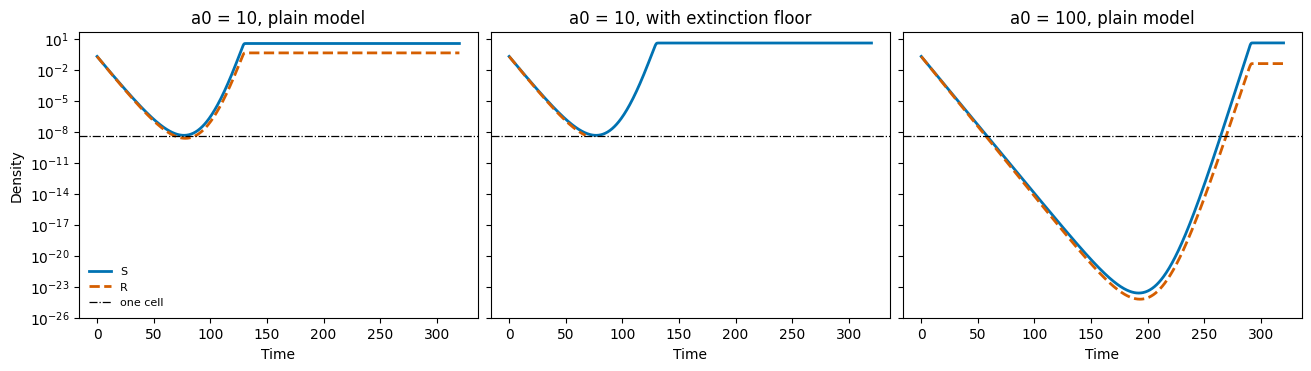

a0 = 10: lowest S = 4.6e-09, lowest R = 2.4e-09 | plain model: S viable, R persists (f_R = 0.109) | with floor: R eradicated, S survives
a0 = 100: lowest S = 2.5e-24, lowest R = 6.2e-25 | plain model: S viable, R persists (f_R = 0.010) | with floor: community eradicated


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True, sharey=True)
for ax, (name, a0, floor) in zip(axes, [("a0 = 10, plain model", 10.0, None),
                                         ("a0 = 10, with extinction floor", 10.0, engine.EXTINCTION_FLOOR),
                                         ("a0 = 100, plain model", 100.0, None)]):
    t_ = engine.simulate(P, a0, 10.0, t_end=320, dt=0.5, floor=floor)
    ax.semilogy(t_.t, np.where(t_.ns > 0, t_.ns, np.nan), color=OKABE_ITO["blue"], lw=2, label="S")
    ax.semilogy(t_.t, np.where(t_.nr > 0, t_.nr, np.nan), color=OKABE_ITO["vermillion"], lw=2, ls="--", label="R")
    ax.axhline(engine.EXTINCTION_FLOOR, color="black", lw=0.9, ls="-.", label="one cell")
    ax.set(title=name, xlabel="Time", ylim=(1e-26, 50))
axes[0].set_ylabel("Density"); axes[0].legend(frameon=False, fontsize=8)
plt.show()
for a0 in (10.0, 100.0):
    r = engine.compute_endpoints(a0=a0)
    print(f"a0 = {a0:g}: lowest S = {r['ns_min']:.1e}, lowest R = {r['nr_min']:.1e} | plain model: {r['outcome']} "
          f"(f_R = {r['f_R_final']:.3f}) | with floor: {r['outcome_floor']}")

**(b) If nothing removes the antibiotic it never clears.** With κ_b = d_a = φ_max = 0 the antibiotic
stays at its dose, lysis never stops and both populations decay forever. There is no steady state,
and any "final resistant fraction" only reflects when the run was stopped. The engine labels such
runs `community collapsed` and stores their composition endpoints as NaN.

In [12]:
p_dead = replace(P, kappa_b=0.0, d_a=0.0, phi_max=0.0)
for T in (150, 400, 1500):
    t_ = engine.integrate(p_dead, BASE_A0, BASE_I, stages=((float(T), 1.0),), adaptive=False)
    print(f"stopped at t = {T:>4}: S = {t_.ns[-1]:.1e}, R = {t_.nr[-1]:.1e}, apparent f_R = {np.exp(t_.ln_nr[-1] - np.logaddexp(t_.ln_ns[-1], t_.ln_nr[-1])):.2e}")
r = engine.compute_endpoints({"kappa_b": 0.0, "d_a": 0.0, "phi_max": 0.0})
print("engine:", r["outcome"], "| f_R stored as", r["f_R_final"], "| with floor:", r["outcome_floor"])
record("9b. never-cleared antibiotic is labelled collapsed", 0.0, 0.0, passed=r["outcome"] == "community collapsed" and np.isnan(r["f_R_final"]))

stopped at t =  150: S = 1.1e-14, R = 2.9e-15, apparent f_R = 2.00e-01
stopped at t =  400: S = 9.8e-37, R = 2.4e-38, apparent f_R = 2.44e-02
stopped at t = 1500: S = 7.7e-134, R = 7.6e-140, apparent f_R = 9.83e-07
engine: community collapsed | f_R stored as nan | with floor: community eradicated
PASS  9b. never-cleared antibiotic is labelled collapsed: 0 (limit 0)


**(c) "Steady state" means the nutrient has run out.** This is a closed batch culture: growth and
(growth-dependent) lysis both stop when the nutrient is used up, and the populations then stay
frozen. The final state is the composition of that stationary culture after one dose, not an
equilibrium that further dosing would return to.

**(d) "Recovery time" in the earlier notebooks included ordinary growth.** It was the time for S to
reach 90% of its final density counted from t = 0, so it was non-zero even with no drug. The engine
now reports two separate quantities: `t_regain_S` (time for S to get back to its starting density
after a dip; 0 if there is no dip) and `t_90_final_S` (the old quantity, under an honest name).

In [13]:
for a0 in (0.0, 1.0, 2.15, 5.0):
    r = engine.compute_endpoints(a0=a0)
    print(f"a0 = {a0:>4}: peak S loss = {r['peak_loss_S']:.3f} | recovery from the dip t_regain_S = {r['t_regain_S']:>5} | "
          f"time to 90% of final t_90_final_S = {r['t_90_final_S']}")
r0 = engine.compute_endpoints(a0=0.0)
record("9d. no drug: recovery time is zero", r0["t_regain_S"], 0.0)

a0 =  0.0: peak S loss = 0.000 | recovery from the dip t_regain_S =   0.0 | time to 90% of final t_90_final_S = 3.5
a0 =  1.0: peak S loss = 0.000 | recovery from the dip t_regain_S =   0.0 | time to 90% of final t_90_final_S = 5.5
a0 = 2.15: peak S loss = 0.394 | recovery from the dip t_regain_S =   8.5 | time to 90% of final t_90_final_S = 13.5
a0 =  5.0: peak S loss = 0.999 | recovery from the dip t_regain_S =  71.5 | time to 90% of final t_90_final_S = 76.5
PASS  9d. no drug: recovery time is zero: 0 (limit 0)


**(e) Other structural points to keep in mind when reading the sweeps**

- The inhibitor dose i is a constant: the model has no inhibitor decay. i and h_i act only through
  ι = i^h_i/(1 + i^h_i), and d_b only through d_b·ι (check 7), so the three inhibitor parameters
  have two independent degrees of freedom.
- c appears in two places (private protection β and antibiotic degradation by living R, φ), so its
  effect cannot be attributed to one mechanism without the ablation in notebook 04.
- Free enzyme is only removed by the inhibitor (d_b·ι·b). With no inhibitor it never decays.
- The model has two strains only. Shannon diversity over two strains is a function of the resistant
  fraction alone and cannot distinguish "R gone" from "S gone".
- There is one dose at t = 0. Periodic dosing is not part of this model.

## Summary

In [14]:
summary = pd.DataFrame(CHECKS)
print(f"{int(summary['pass'].sum())} of {len(summary)} checks passed")
assert summary["pass"].all()
summary.to_csv(TABLES / "model_verification_checks.csv", index=False)
pd.set_option("display.max_colwidth", 100)
summary

34 of 34 checks passed


,check,value,limit,pass
0,1. rhs vs SI transcription (max relative difference),1.265993e-15,1.000000e-12,True
1,2. Fig. 2C: |S(20) - 2.2| read off the figure,2.538156e-02,1.500000e-01,True
2,2. Fig. 2C: |R(20) - 1.7| read off the figure,4.231968e-02,1.500000e-01,True
3,2. Fig. 2C inset: |f_R(20) - 0.43|,2.555086e-03,3.000000e-02,True
4,"3. Fig. 2D: A=100, I=0.32 ends majority resistant",1.392349e-01,5.000000e-01,True
5,"3. Fig. 2D: A=6.8, I=10 ends majority sensitive",1.616280e-01,5.000000e-01,True
6,"3. Fig. 2D: A=100, I=0.32 lowest density within 10x of 1e-3",2.112443e-01,1.000000e+00,True
7,"3. Fig. 2D: A=6.8, I=10 lowest density within 10x of 1e-6",3.856177e-01,1.000000e+00,True
8,3. Fig. 3A: 'Higher burden (α = 0.8)' lowers the resistant fraction at almost all doses (share g...,0.000000e+00,1.000000e-01,True
9,3. Fig. 3A: 'Higher Bla inhibition (c = 0.9)' lowers the resistant fraction at almost all doses ...,0.000000e+00,1.000000e-01,True
